In [1]:
# Take a trained model and transform the parameters such that the resulting invariant set is the unit ball

import os
import sys
from pathlib import Path
import numpy as np
import mlflow
import matplotlib.pyplot as plt
# %matplotlib widget
%load_ext autoreload
%autoreload 2

project_root = Path.cwd().parent.parent
print(project_root)

/Users/jack/Documents/01_Git/01_promotion/genSecSysId/python


In [2]:
from sysid.config import allow_file_store
allow_file_store()

# Set MLflow tracking URI
mlflow_uri = 'http://mlflowui.informatik.uni-stuttgart.de/'
mlflow.set_tracking_uri(mlflow_uri)

print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")

experiment_name = 'duffing-soft-12'

MLflow tracking URI: http://mlflowui.informatik.uni-stuttgart.de/


# Load model from run id

In [3]:
import torch
from sysid.models.factory import load_model
from sysid.config import Config
from sysid.data import DataNormalizer

run_id = '3915a97b4fcd4c91a8101da09ccba3ce'
print(f"Loading model from run {run_id}...")

# Models are logged as raw .pt files under artifact path "models" (not "model").
# mlflow.pytorch.log_model was never called, so mlflow.pytorch.load_model won't work.
outputs_dir = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="outputs")
models_dir  = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="models")

config = Config.from_yaml(os.path.join(outputs_dir, "config.yaml"))
model  = load_model(os.path.join(models_dir, "best_model.pt"), config)

normalizer_path = mlflow.artifacts.download_artifacts(
    run_id=run_id, artifact_path="models/normalizer.json"
)
normalizer = DataNormalizer.load(normalizer_path)

print(f"Model loaded: {type(model).__name__}")
print(model)

print(f"\nNormalizer loaded: {type(normalizer).__name__}")

Loading model from run 3915a97b4fcd4c91a8101da09ccba3ce...


Model loaded: SimpleLure
SimpleLure(
  (lure): LureSystem(
    (Delta): DznActivation()
  )
)

Normalizer loaded: DataNormalizer


P = [[356705.7950231    7776.70377786]
 [  7776.70377786 745236.42019738]] 
X = [[ 2.80406870e-06 -2.92610654e-08]
 [-2.92610654e-08  1.34216140e-06]] 
s = 0.0007659361983875278 
H = [[ 1.40829633e-03 -2.57009333e-04]
 [ 1.51640306e-03  2.49721873e-04]
 [-1.42850656e-03  1.99188388e-04]
 [-8.60906278e-04 -1.62805868e-01]
 [ 3.46887320e-02  1.35691537e-01]
 [ 4.64096870e-01  2.77288820e-02]
 [-1.80564942e-02  1.12995192e-01]
 [ 1.75846904e-03  1.71359300e-03]
 [ 1.45706793e-03  1.38693812e-04]
 [-1.19011926e-03  1.79666604e-05]
 [ 1.50876115e-03  2.45609265e-04]
 [-1.50896355e-03 -3.76214825e-04]
 [-8.07916790e-01 -2.63849514e-01]
 [ 2.17426773e-01  4.51346590e-02]
 [ 1.44485171e-03  8.25931847e-05]
 [-1.46104163e-03 -6.69871446e-05]
 [-5.47931544e-01  2.96040122e-02]
 [ 3.22415002e-01 -7.65652073e-02]
 [-6.30691328e-03 -1.39693990e-01]
 [-7.53462834e-02  6.57616175e-02]
 [ 3.78720931e-01 -9.66026636e-02]
 [-2.82519042e-02 -1.26221867e-01]
 [-2.91770861e-01  1.23922340e-01]
 [ 1.1345202

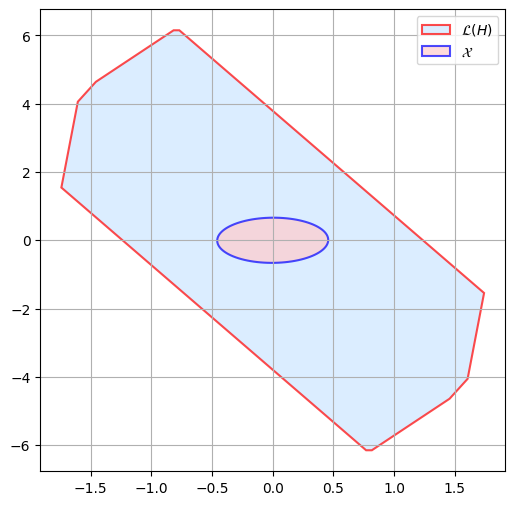

In [6]:
from sysid.utils import plot_ellipse, plot_polytope 

P = model.P.detach().numpy()
X = np.linalg.inv(P)
s = model.s.detach().numpy()
L = model.L.detach().numpy()
H = L @ X

alpha= float(1.0 / (1.0 + np.exp(-model.tau.detach().numpy())))


X_orig = X.copy()
H_orig = H.copy()
s_orig = s.copy()

print(f'P = {P} \nX = {X} \ns = {s} \nH = {H}, alpha = {alpha}')

fig, ax = plt.subplots(figsize=(6,6))

plot_polytope(ax, H, linetype='b--', name=r'$\mathcal{L}(H)$')
plot_ellipse(ax, X, s, linetype='r--', fill=True, name=r'$\mathcal{X}$')
ax.legend()
ax.grid()

In [10]:
model.post_process()
alpha_post= float(1.0 / (1.0 + np.exp(-model.tau.detach().numpy())))
print(f'alpha_post = {alpha_post}')

alpha_post = 0.9929373751739091


In [8]:
A, B, B2, C, C2 = model.A.detach().numpy(), model.B.detach().numpy(), model.B2.detach().numpy(), model.C.detach().numpy(), model.C2.detach().numpy()
D21 = model.D21.detach().numpy()
D = model.D.detach().numpy()
D12 = model.D12.detach().numpy()

nx, nd, ny, nw = A.shape[0], B.shape[1], C.shape[0], B2.shape[1]
nz = nw

# Make an alpha sweep

## old certificate

In [12]:
import cvxpy as cp
eps = 1e-6

alphas = np.linspace(0.99, 0.99999999, 100)
s_values = []
sigma_us = []
P_values = []
Ls = []
Ms = []

for alpha in alphas:
    # print(f'---CHECK REGIONAL STABILITY FOR alpha = {alpha} ---')
    # Decision variables
    P = cp.Variable((nx, nx), symmetric=True)
    L = cp.Variable((nz, nx))
    m = cp.Variable((nz, 1))
    M = cp.diag(m)

    # S_hat for optimizing s
    S_hat = cp.Variable((1, 1))

    # Constraints
    constraints = []

    # Main LMI: F <= -eps*I
    F = cp.bmat(
        [
            [-(alpha**2) * P, np.zeros((nx, nd)), P @ C2.T + L.T, P @ A.T],
            [np.zeros((nd, nx)), -np.eye(nd), D21.T, B.T],
            [C2 @ P + L, D21, -2 * M, M @ B2.T],
            [A @ P, B, B2 @ M, -P],
        ]
    )
    nF = F.shape[0]
    constraints.append(F << -eps * np.eye(nF))

    # Locality constraints: [S_hat, li; li', P] >= eps*I for each row of L
    for i in range(nz):
        li = L[i, :].reshape((1, -1), order="C")
        locality_lmi = cp.bmat([[S_hat, li], [li.T, P]])
        constraints.append(locality_lmi >> eps * np.eye(nx + 1))

    # Objective
    objective = cp.Minimize(S_hat)

    # Solve
    problem = cp.Problem(objective, constraints)
    # print(f"Solving SDP with {len(constraints)} constraints using MOSEK...")
    problem.solve(solver=cp.MOSEK, verbose=False)
    if problem.status not in ["optimal"]:
        print(f'Regional stability is infeasible for alpha = {alpha}.')
        s_values.append(np.nan)
        sigma_us.append(np.nan)
        P_values.append(np.nan)
        Ls.append(np.nan)
        Ms.append(np.nan)
        continue
        
    
    s = np.sqrt(1/S_hat.value)
    sigma_u = np.sqrt(s**2*(1 - alpha**2) )
    print(f'alpha = {alpha:.4f}, s = {s[0,0]:.4f}, s_hat = {S_hat.value[0,0]:.4f}, sigma_u = {sigma_u[0,0]:.4f}')
    s_values.append(s[0,0])
    P_values.append(P.value)
    sigma_us.append(sigma_u[0,0])
    Ms.append(M.value)
    Ls.append(L.value)

alpha = alphas[np.nanargmax(sigma_us)]
s = s_values[np.nanargmax(sigma_us)]
P = P_values[np.nanargmax(sigma_us)]
sigma_u = sigma_us[np.nanargmax(sigma_us)]
L = Ls[np.nanargmax(sigma_us)]
M = Ms[np.nanargmax(sigma_us)]

X = np.linalg.inv(P)
H = L @ X

Regional stability is infeasible for alpha = 0.99.
Regional stability is infeasible for alpha = 0.99010101.
Regional stability is infeasible for alpha = 0.99020202.
Regional stability is infeasible for alpha = 0.99030303.
Regional stability is infeasible for alpha = 0.99040404.
Regional stability is infeasible for alpha = 0.99050505.
Regional stability is infeasible for alpha = 0.99060606.
Regional stability is infeasible for alpha = 0.99070707.
Regional stability is infeasible for alpha = 0.99080808.
Regional stability is infeasible for alpha = 0.9909090899999999.
Regional stability is infeasible for alpha = 0.9910101.
Regional stability is infeasible for alpha = 0.99111111.
Regional stability is infeasible for alpha = 0.99121212.
Regional stability is infeasible for alpha = 0.99131313.
Regional stability is infeasible for alpha = 0.9914141399999999.
Regional stability is infeasible for alpha = 0.99151515.
Regional stability is infeasible for alpha = 0.99161616.
Regional stability is 

max sigma_u = 0.4033 at alpha = 0.9966


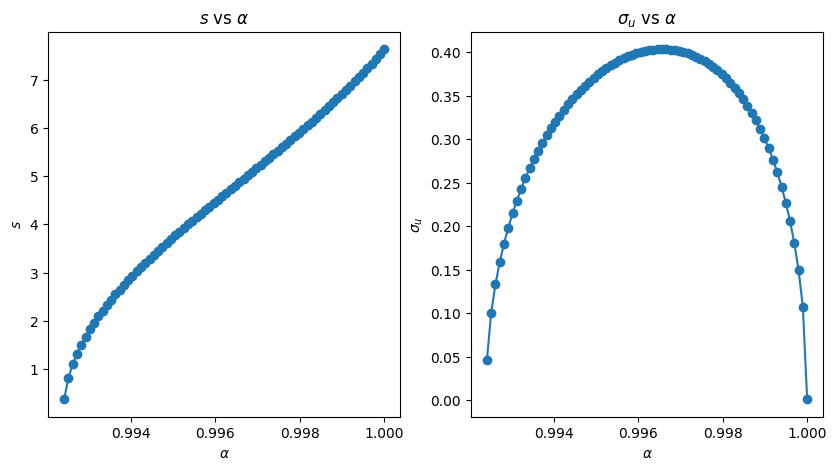

In [13]:
import tikzplotlib
def plot_sigma_vs_alpha(alphas, s_values, sigma_us):
    fig, ax = plt.subplots(figsize=(10, 5), nrows=1, ncols=2)
    ax[0].plot(alphas, s_values, marker='o')
    ax[0].set_xlabel(r'$\alpha$')
    ax[0].set_ylabel(r'$s$')
    ax[0].set_title(r'$s$ vs $\alpha$')

    ax[1].plot(alphas, sigma_us, marker='o')
    ax[1].set_xlabel(r'$\alpha$')
    ax[1].set_ylabel(r'$\sigma_u$')
    ax[1].set_title(r'$\sigma_u$ vs $\alpha$')

plot_sigma_vs_alpha(alphas, s_values, sigma_us)

print(f'max sigma_u = {np.nanmax(sigma_us):.4f} at alpha = {alphas[np.nanargmax(sigma_us)]:.4f}')
tikzplotlib.save(f'{project_root}/results/figures/Duffing-old-certificate-alpha-analysis.tex')

# print(f'P = {P}, s = {s:.4f}, sigma_u = {sigma_u:.4f} at alpha = {alpha:.4f}, L = {L}', f'M = {M}')


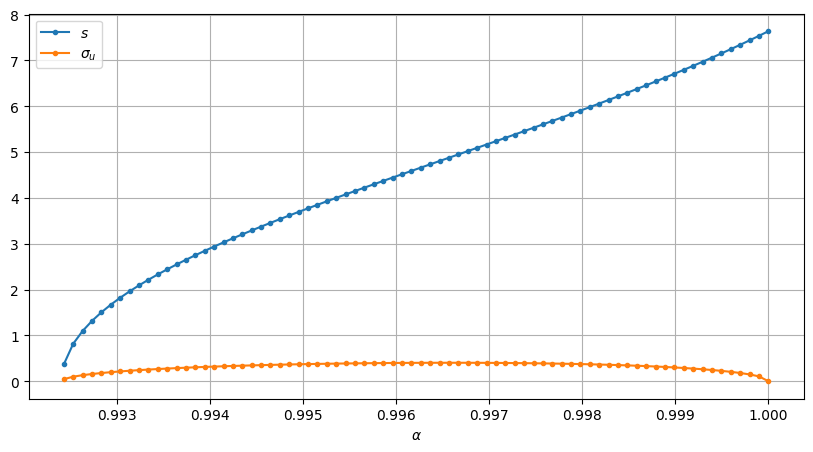

In [15]:
fig2, ax2 = plt.subplots(1, 1, figsize=(10, 5))
ax2.plot(alphas, s_values, '.-', label=r'$s$')
ax2.plot(alphas, sigma_us, '.-', label=r'$\sigma_u$')
ax2.set_xlabel(r'$\alpha$')
ax2.grid()
ax2.legend()
fig.tight_layout()
tikzplotlib.save(f'{project_root}/results/figures/Duffing-admissible-input-sigma-vs-alpha-old.tex', fig2)

# New conditions

In [14]:
alphas = np.linspace(0.99, 0.99999999, 100)
s_values = []
sigma_us = []
P_values = []
Ls = []
Ms = []

for alpha in alphas:
    # print(f'---CHECK REGIONAL STABILITY FOR alpha = {alpha} ---')
    # Decision variables
    P = cp.Variable((nx, nx), symmetric=True)
    L = cp.Variable((nz, nx))
    m = cp.Variable((nz, 1))
    M = cp.diag(m)

    # S_hat for optimizing s
    S_hat = cp.Variable((1, 1))

    # Constraints
    constraints = []

    # Main LMI: F <= -eps*I
    F = cp.bmat(
        [
            [-(alpha**2) * P, np.zeros((nx, nd)), P @ C2.T + L.T, P @ A.T],
            [np.zeros((nd, nx)), -S_hat, D21.T, B.T],
            [C2 @ P + L, D21, -2 * M, M @ B2.T],
            [A @ P, B, B2 @ M, -P],
        ]
    )
    nF = F.shape[0]
    constraints.append(F << -eps * np.eye(nF))

    # Locality constraints: [S_hat, li; li', P] >= eps*I for each row of L
    for i in range(nz):
        li = L[i, :].reshape((1, -1), order="C")
        locality_lmi = cp.bmat([[np.array([[1.0]]), li], [li.T, P]])
        constraints.append(locality_lmi >> eps * np.eye(nx + 1))

    # Objective
    objective = cp.Minimize(S_hat)

    # Solve
    problem = cp.Problem(objective, constraints)
    # print(f"Solving SDP with {len(constraints)} constraints using MOSEK...")
    try:
        problem.solve(solver=cp.MOSEK, verbose=False)
    except:
        print(f'Error occurred while solving SDP for alpha = {alpha}.')
        s_values.append(np.nan)
        sigma_us.append(np.nan)
        P_values.append(np.nan)
        Ls.append(np.nan)
        Ms.append(np.nan)
        continue
    if problem.status not in ["optimal"]:
        print(f'Regional stability is infeasible for alpha = {alpha}.')
        s_values.append(np.nan)
        sigma_us.append(np.nan)
        P_values.append(np.nan)
        Ls.append(np.nan)
        Ms.append(np.nan)
        continue
        
    
    s = np.sqrt(1/S_hat.value)
    sigma_u = np.sqrt(s**2*(1 - alpha**2) )
    print(f'alpha = {alpha:.4f}, s = {s[0,0]:.4f}, s_hat = {S_hat.value[0,0]:.4f}, sigma_u = {sigma_u[0,0]:.4f}')
    s_values.append(s[0,0])
    P_values.append(P.value)
    sigma_us.append(sigma_u[0,0])
    Ms.append(M.value)
    Ls.append(L.value)



Error occurred while solving SDP for alpha = 0.99.
Regional stability is infeasible for alpha = 0.99010101.
Error occurred while solving SDP for alpha = 0.99020202.
Error occurred while solving SDP for alpha = 0.99030303.
Error occurred while solving SDP for alpha = 0.99040404.
Error occurred while solving SDP for alpha = 0.99050505.
Error occurred while solving SDP for alpha = 0.99060606.
Error occurred while solving SDP for alpha = 0.99070707.
Error occurred while solving SDP for alpha = 0.99080808.
Error occurred while solving SDP for alpha = 0.9909090899999999.
Error occurred while solving SDP for alpha = 0.9910101.
Error occurred while solving SDP for alpha = 0.99111111.
Error occurred while solving SDP for alpha = 0.99121212.
Error occurred while solving SDP for alpha = 0.99131313.
Error occurred while solving SDP for alpha = 0.9914141399999999.
Error occurred while solving SDP for alpha = 0.99151515.
Error occurred while solving SDP for alpha = 0.99161616.
Error occurred while s

In [136]:
alpha = alphas[np.nanargmax(sigma_us)]
s = s_values[np.nanargmax(sigma_us)]
P = P_values[np.nanargmax(sigma_us)]
sigma_u = sigma_us[np.nanargmax(sigma_us)]
L = Ls[np.nanargmax(sigma_us)]
M = Ms[np.nanargmax(sigma_us)]

X = np.linalg.inv(P)
H = L @ X

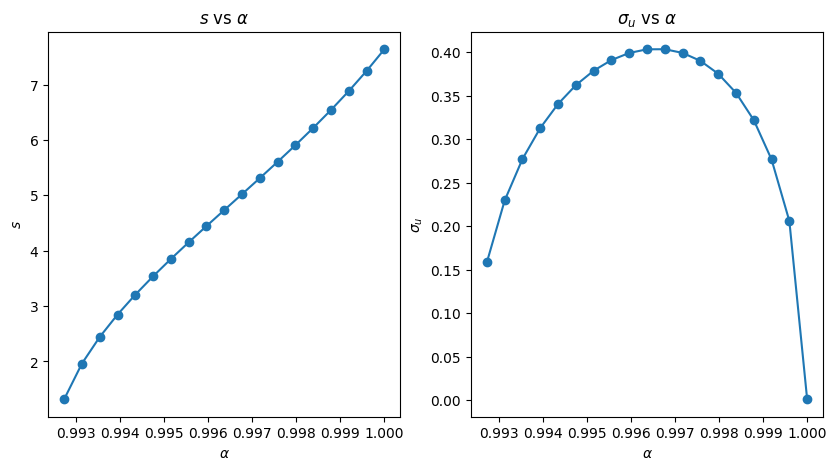

In [137]:
plot_sigma_vs_alpha(alphas, s_values, sigma_us)
tikzplotlib.save(f'{project_root}/results/figures/Duffing-new-certificate-alpha-analysis.tex')

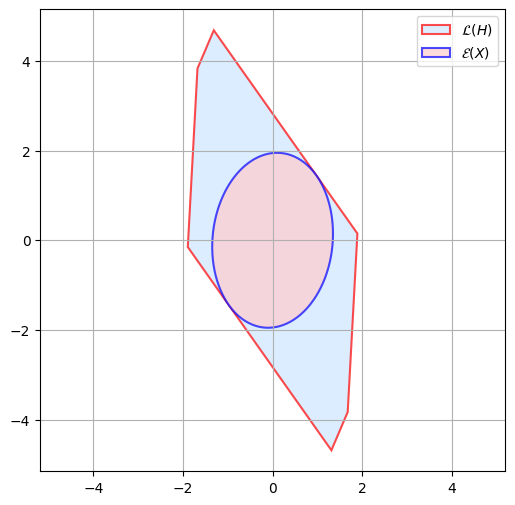

In [138]:
fig, ax = plt.subplots(figsize=(6,6))

plot_polytope(ax, H, linetype='b--', name=r'$\mathcal{L}(H)$')
plot_ellipse(ax, X, 1.0, linetype='r--', fill=True, name=r'$\mathcal{E}(X)$')
ax.legend()
ax.grid()
ax.axis('equal')

tikzplotlib.save(f'{project_root}/results/figures/Duffing-ellipse-new-certificate.tex')

## transformed state new conditions

In [139]:
X = 0.5 * (X + X.T)                 # symmetrize before Cholesky
R = np.linalg.cholesky(X)
T = R.T
Tinv = np.linalg.inv(T)

tilde_A = T @ A @ np.linalg.inv(T)
tilde_B = T @ B
tilde_B2 = T @ B2
tilde_C = C @ np.linalg.inv(T)
tilde_C2 = C2 @ np.linalg.inv(T)

In [ ]:
alphas = np.linspace(0.99, 0.99999999, 100)
# alphas = [0.99]
s_values = []
sigma_us = []
tilde_Ns = []
Lambdas = []

for alpha in alphas:

    N_tilde = cp.Variable((nz, nx))
    la = cp.Variable((nz, 1))
    Lambda = cp.diag(la)

    # S_hat for optimizing s
    S_hat = cp.Variable((1, 1))

    # Constraints
    constraints = []

    # Main LMI: F <= -eps*I
    F = cp.bmat(
        [
            [-(alpha**2) * np.eye(nx), np.zeros((nx, nd)), tilde_C2.T @ Lambda + N_tilde.T, tilde_A.T],
            [np.zeros((nd, nx)), -S_hat, D21.T @ Lambda, tilde_B.T],
            [Lambda @ tilde_C2 + N_tilde, Lambda @ D21, -2 * Lambda, tilde_B2.T],
            [tilde_A, tilde_B, tilde_B2,-np.eye(nx)],
        ]
    )
    nF = F.shape[0]
    constraints.append(F << -eps * np.eye(nF))

    # Locality constraints: [S_hat, li; li', P] >= eps*I for each row of L
    for i in range(nz):
        tilde_n_i = N_tilde[i, :].reshape((1, -1), order="C")
        lambda_i = la[i].reshape((1,-1), order="C")
        locality_lmi = cp.bmat([[lambda_i, tilde_n_i], [tilde_n_i.T, lambda_i*np.eye(nx)]])
        constraints.append(locality_lmi >> eps * np.eye(nx + 1))

    # Objective
    objective = cp.Minimize(S_hat)

    # Solve
    problem = cp.Problem(objective, constraints)
    # print(f"Solving SDP with {len(constraints)} constraints using MOSEK...")
    try:
        problem.solve(solver=cp.MOSEK, verbose=False)
    except:
        print(f'Regional stability mosek failure = {alpha}.')
    
    if problem.status not in ["optimal"]:
        print(f'Regional stability is infeasible for alpha = {alpha}.')
        s_values.append(np.nan)
        sigma_us.append(np.nan)
        tilde_Ns.append(np.nan)
        Lambdas.append(np.nan)
        continue
        
    s_tilde = np.sqrt(1/S_hat.value)
    sigma_u = np.sqrt(s_tilde**2*(1 - alpha**2))
    print(f'alpha = {alpha:.4f}, s_tilde = {s_tilde[0,0]:.4f}, s_hat = {S_hat.value[0,0]:.4f}, sigma_u = {sigma_u[0,0]:.4f}')
    s_values.append(s_tilde[0,0])
    sigma_us.append(sigma_u[0,0])
    Lambdas.append(Lambda.value)
    tilde_Ns.append(N_tilde.value)


Regional stability is infeasible for alpha = 0.96.
Regional stability is infeasible for alpha = 0.9604040403030303.
Regional stability is infeasible for alpha = 0.9608080806060606.
Regional stability is infeasible for alpha = 0.9612121209090909.
Regional stability is infeasible for alpha = 0.9616161612121211.
Regional stability is infeasible for alpha = 0.9620202015151514.
Regional stability is infeasible for alpha = 0.9624242418181818.
Regional stability is infeasible for alpha = 0.9628282821212121.
Regional stability is infeasible for alpha = 0.9632323224242424.
Regional stability is infeasible for alpha = 0.9636363627272727.
Regional stability is infeasible for alpha = 0.964040403030303.
Regional stability is infeasible for alpha = 0.9644444433333333.
Regional stability is infeasible for alpha = 0.9648484836363636.
Regional stability is infeasible for alpha = 0.9652525239393939.
Regional stability is infeasible for alpha = 0.9656565642424242.
Regional stability is infeasible for alp

In [203]:
len(alphas)

100

In [ ]:
alpha = alphas[np.nanargmax(sigma_us)]
s_tilde = s_values[np.nanargmax(sigma_us)]
sigma_u = sigma_us[np.nanargmax(sigma_us)]
Lambda = Lambdas[np.nanargmax(sigma_us)]

tilde_N = tilde_Ns[np.nanargmax(sigma_us)]
tilde_H = np.linalg.inv(Lambda) @ tilde_N

tilde_X = np.eye(nx)

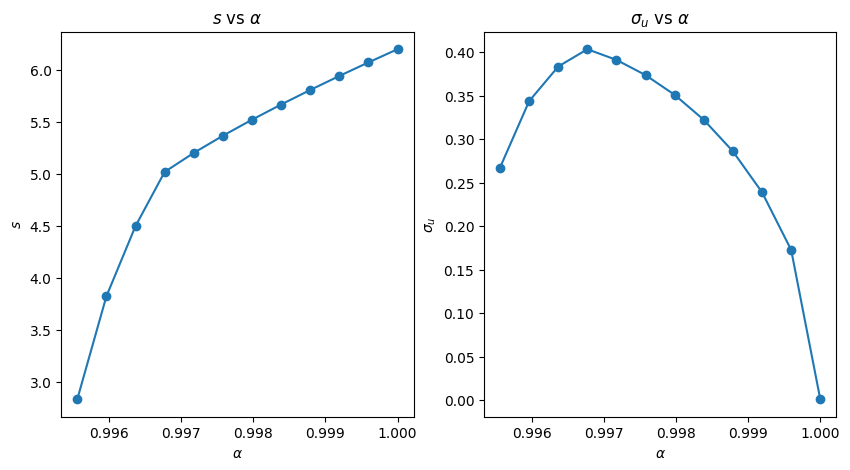

In [142]:
plot_sigma_vs_alpha(alphas, s_values, sigma_us)
tikzplotlib.save(f'{project_root}/results/figures/2D-new-transformed-certificate-alpha-analysis.tex')

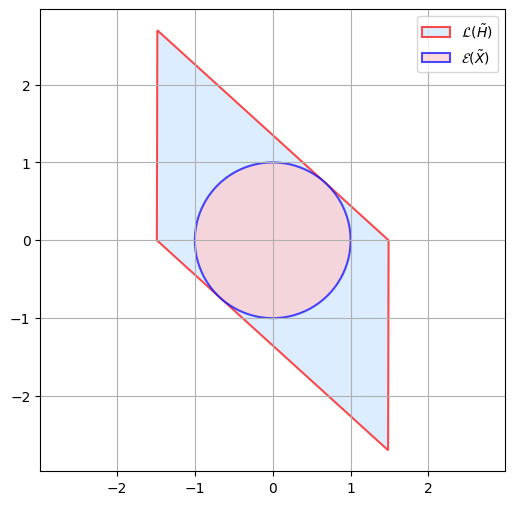

In [143]:
fig, ax = plt.subplots(figsize=(6,6))

plot_polytope(ax, tilde_H, linetype='b--', name=r'$\mathcal{L}(\tilde{H})$')
plot_ellipse(ax, tilde_X, 1.0, linetype='r--', fill=True, name=r'$\mathcal{E}(\tilde{X})$')
ax.legend()
ax.grid()
ax.axis('equal')

tikzplotlib.save(f'{project_root}/results/figures/Duffing-ellipse-transformed-certificate.tex')

# Plot sample predictions

In [144]:
def dzn(z):
    """Scalar deadzone: max(|z| - 1, 0) * sign(z)."""
    return np.maximum(np.abs(z) - 1, 0.0) * np.sign(z)

In [145]:
class LureModel:
    def __init__(self, A, B, B2, C, C2, D, D12, D21, psi=dzn):
        self.A = A
        self.B = B
        self.B2 = B2
        self.C = C
        self.C2 = C2
        self.D = D
        self.D12 = D12
        self.D21 = D21
        self.psi = psi
        self.nx = A.shape[0]
        self.nd = B.shape[1]
        self.ne = C.shape[0]
        self.nz = B2.shape[1]
    def step(self, x, u):
        u = np.asarray(u).reshape(-1)
        z = self.C2 @ x + self.D21 @ u
        w = self.psi(z)
        y_hat = self.C @ x + self.D @ u + self.D12 @ w
        x = self.A @ x + self.B @ u + self.B2 @ w
        return y_hat, x

    def simulate(self, x0, u_seq, apply_input_filter=False):
        X = [x0.copy()]
        Y = []
        u_filtered_seq = []
        for u in u_seq:
            u = np.asarray(u).reshape(-1)
            if apply_input_filter:
                Vx = X[-1].reshape(1,self.nx) @ self.X @ X[-1].reshape(self.nx,1)
                if u**2 > self.s**2 - self.alpha**2 * Vx:
                    u_filtered = np.sqrt(self.s**2 - self.alpha**2 * Vx)*np.sign(u)
                    print(f'u is filtered from {u} to {u_filtered.reshape(-1)}')
                    u = u_filtered.reshape(-1)

            y_hat, x = self.step(X[-1], u)
            u_filtered_seq.append(u)
            X.append(x)
            Y.append(y_hat)
        return np.array(X), np.array(Y).reshape(-1), np.array(u_filtered_seq)

    def set_X_s_alpha(self, X, s, alpha):
        self.X = X
        self.s = s
        self.alpha = alpha
        self.P = np.linalg.inv(X)

In [146]:
mdl = LureModel(A, B, B2, C, C2, D, D12, D21)
mdl.set_X_s_alpha(X,s,alpha)
mdlTransformed = LureModel(tilde_A, tilde_B, tilde_B2, tilde_C, tilde_C2, D, D12, D21)
mdlTransformed.set_X_s_alpha(tilde_X, s_tilde, alpha)

In [156]:
LP_CUTOFF   = 2.0  # Hz  LP filter cutoff
LP_ORDER    =   4   # Butterworth filter order
ENV_DECAY   = 0.9  # mild exponential envelope strength over one trajectory
TS = 0.05
N = 100
rng_dbg = np.random.default_rng(0)

In [157]:
def make_u(rng, T, amp_max, f_cut=LP_CUTOFF, order=LP_ORDER, env_decay=ENV_DECAY):
    """Low-pass filtered white noise with optional exponential decay envelope.

    White noise is generated at the sample rate 1/TS and filtered with a
    Butterworth LP filter of the given cutoff frequency (Hz) and order.
    The resulting signal is multiplied by exp(-env_decay * t_norm), where
    t_norm spans [0, 1], then peak-normalised to a random fraction of amp_max.
    """
    from scipy.signal import butter, filtfilt
    # design filter (normalised cutoff = f_cut / Nyquist)
    b, a = butter(order, f_cut / (0.5 / TS), btype='low')
    # generate and filter; use extra samples to avoid edge transients
    pad   = 4 * order
    noise = rng.standard_normal(T + pad)
    u_filt = filtfilt(b, a, noise)[pad:]
    # apply mild exponential decay envelope across trajectory length
    t_norm = np.linspace(0.0, 1.0, T)
    envelope = np.exp(-env_decay * t_norm)
    u_filt = u_filt * envelope
    # peak-normalise to a random fraction of amp_max
    peak = np.max(np.abs(u_filt))
    if peak > 0:
        u_filt = u_filt / peak * rng.uniform(0.0, amp_max)
    return u_filt


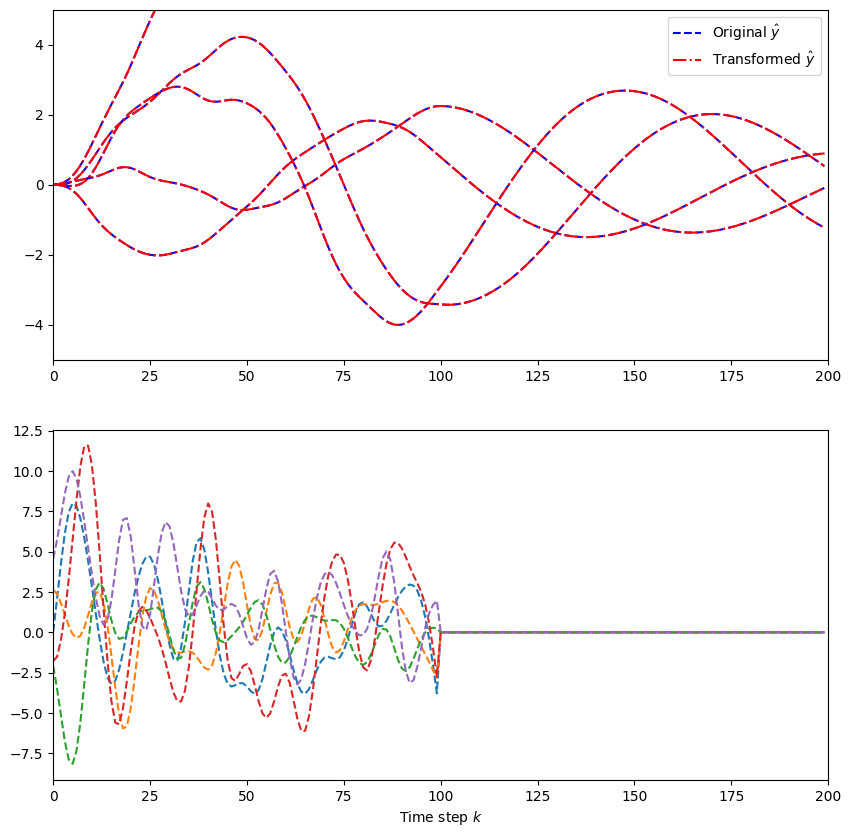

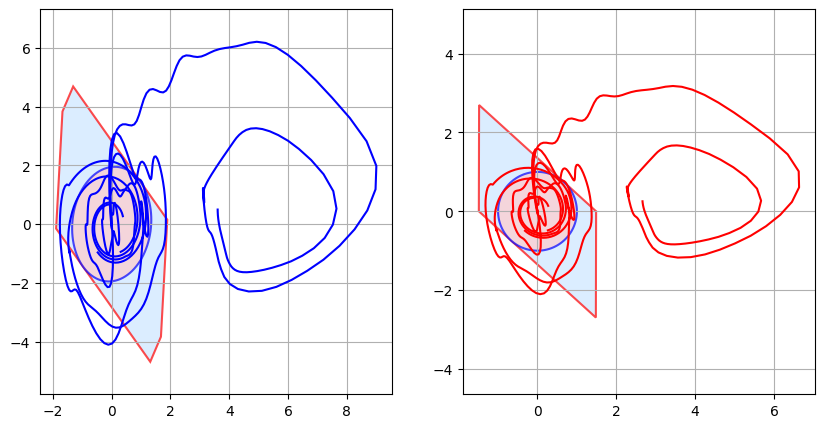

In [173]:
# plot 4 samples

fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(10,10))
fig2, axs2 = plt.subplots(nrows=1, ncols=2, figsize=(10,5))
for i in range(5):
    u = make_u(rng_dbg, N, 12.0)
    u = np.concatenate([u, np.zeros(N)])  # append zeros to see decay
    x0 = np.array([0.0, 0.0])
    x, y_hat,_ = mdl.simulate(x0, u, apply_input_filter=False)
    tilde_x, tilde_y_hat, _ = mdlTransformed.simulate(x0, u, apply_input_filter=False)

    # x_filtered, y_hat_filtered, u_filtered = mdl.simulate(x0, u, apply_input_filter=True)
    # tilde_x_filtered, tilde_y_hat_filtered, tilde_u_filtered = mdlTransformed.simulate(x0, u, apply_input_filter=True)
    if i==0:
        axs[0].plot(y_hat, color='blue', linestyle='--', label='Original $\hat{y}$')
        axs[0].plot(tilde_y_hat, color='red', linestyle='-.', label='Transformed $\hat{y}$')
    else:
        axs[0].plot(y_hat, color='blue', linestyle='--')
        axs[0].plot(tilde_y_hat, color='red', linestyle='-.')
    
    
    axs[1].plot(u, linestyle='--', label='Input $u_k$')
    # axs[1].plot(u_filtered, linestyle='--')
    # axs[1].plot(tilde_u_filtered)

    axs2[0].plot(x[:, 0], x[:,1], color='blue')
    axs2[1].plot(tilde_x[:, 0], tilde_x[:,1], color='red')

axs[0].set_xlim([0, 2*N])
axs[0].legend()
axs[0].set_ylim([-5.0,5.0])

axs[1].set_xlabel('Time step $k$')
axs[1].set_xlim([0,2*N])

tikzplotlib.save(f'{project_root}/results/figures/Duffing-simulated-trajectories-and-input.tex', fig)

plot_polytope(axs2[0], H, linetype='b--', name=r'$\mathcal{L}(H)$')
plot_ellipse(axs2[0], X, 1.0, linetype='r--', fill=True, name=r'$\mathcal{E}(X)$')
# axs2[0].plot(x_filtered[:, 0], x_filtered[:,1], color='green', linestyle='--')
axs2[0].axis('equal')
axs2[0].grid()

plot_polytope(axs2[1], tilde_H, linetype='b--', name=r'$\mathcal{L}(\tilde{H})$')
plot_ellipse(axs2[1], tilde_X, 1.0, linetype='r--', fill=True, name=r'$\mathcal{E}(\tilde{X})$')
# axs2[1].plot(tilde_x_filtered[:, 0], tilde_x_filtered[:,1], color='green', linestyle='--')
# axs2[1].plot(x[:, 0], x[:,1], color='blue', linestyle='--')
axs2[1].axis('equal')
axs2[1].grid()

tikzplotlib.save(f'{project_root}/results/figures/Duffing-simulated-trajectories-phase-plane.tex', fig2)

# fig3, ax3 = plt.subplots(figsize=(10,6))
# # ax3.plot(np.abs(x-x_filtered))
# ax3.set_xlabel('Time step $k$')
# ax3.set_ylabel('Error')
# ax3.legend()
# ax3.grid()


# analyze input map

In [193]:
alpha


0.9967676675757575

tilde s = 5.0207, tilde alpha = 0.1000, tilde X = [[1. 0.]
 [0. 1.]]


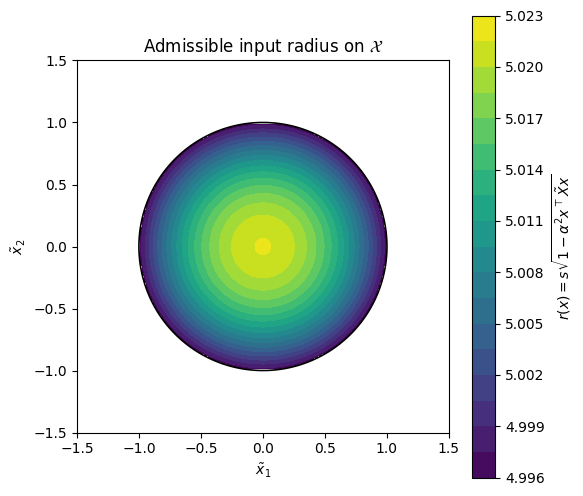

In [194]:
alpha_tmp = 0.1
# Uc = { u \in \Rbb^m | u^T u \leq s^2 (1- \alpha^2 x^T \tilde X x)}
print(f'tilde s = {s_tilde:.4f}, tilde alpha = {alpha_tmp:.4f}, tilde X = {tilde_X}')
# in case \tilde X = I, then Uc = { u \in \Rbb^m | u^T u \leq s^2 (1- \alpha^2 x^T x)}
# we can print a heatmap in the x1-x2 plane to visualize the admissible input
fig, ax = plt.subplots(figsize=(6, 6))
x1 = np.linspace(-1.5, 1.5, 200)
x2 = np.linspace(-1.5, 1.5, 200)
X1, X2 = np.meshgrid(x1, x2)

Z = np.stack([X1.ravel(), X2.ravel()], axis=1)                    # (N, 2)
Vx = np.einsum('ij,jk,ik->i', Z, tilde_X, Z).reshape(X1.shape)     # z_i^T X z_i

budget = s**2 * (1 - alpha_tmp**2 * Vx)
Umax = np.sqrt(np.clip(budget, 0, None))
Umax = np.where(Vx <= 1, Umax, np.nan)          # U is defined only on X

c = ax.contourf(X1, X2, Umax, levels=20, cmap='viridis')
ax.contour(X1, X2, Vx, levels=[1], colors='k', linewidths=1.2)   # boundary of X
fig.colorbar(c, ax=ax, label=r'$r(x) = s\sqrt{1 - \alpha^2 x^\top \tilde X x}$')
ax.set_xlabel(r'$\tilde x_1$')
ax.set_ylabel(r'$\tilde x_2$')
ax.set_title(r'Admissible input radius on $\mathcal{X}$')
ax.set_aspect('equal')
# tikzplotlib.save(f'{project_root}/results/figures/Duffing-admissible-input-transformed-system.tex', fig)


In [217]:
alpha = alphas[np.nanargmax(sigma_us)]
alpha
s

5.021603636833994

In [258]:
def area_under_radius(s, alpha):
    """int_0^1 s*sqrt(1 - alpha^2 rho^2) d rho"""
    return s * (np.sqrt(1 - alpha**2) / 2 + np.arcsin(alpha) / (2 * alpha))

In [259]:
auc_values = []
for alpha, s in zip(s_values, alphas):
    auc_values.append(area_under_radius(alpha,s))


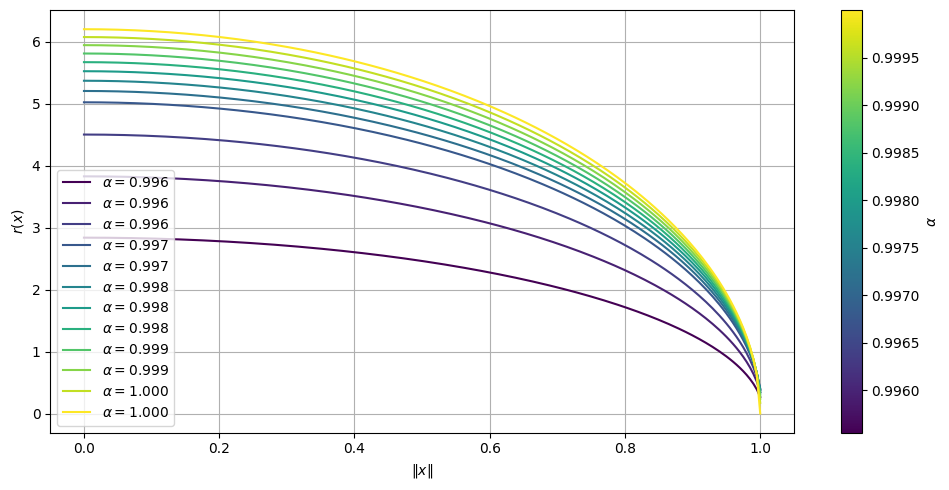

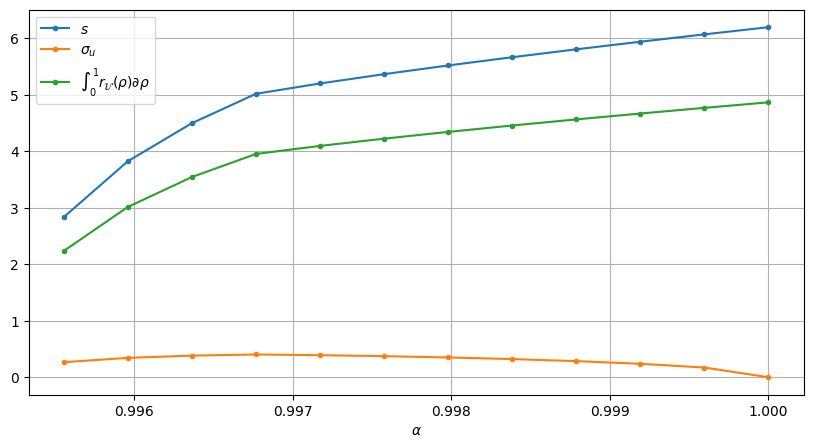

In [263]:
a_arr = np.asarray(alphas, dtype=float)
s_arr = np.asarray(s_values, dtype=float)
auc_arr = np.asarray(auc_values, dtype=float)
ok = ~np.isnan(s_arr)
if not ok.any():
    raise RuntimeError('no feasible alpha in the sweep')
a_ok, s_ok, auc_ok = a_arr[ok], s_arr[ok], auc_arr[ok]

rho = np.linspace(0, 1, 200)
R = s_ok[:, None] * np.sqrt(1 - a_ok[:, None]**2 * rho[None, :]**2)   # (n_alpha, n_rho)

fig, ax1 = plt.subplots(1, 1, figsize=(10,5 ))
norm = plt.Normalize(a_ok.min(), a_ok.max())
for a, r in zip(a_ok, R):
    ax1.plot(rho, r, label=fr'$\alpha={a:.3f}$', color=plt.cm.viridis(norm(a)))
# ax1.plot(rho, R.max(axis=0), 'k--', lw=1.2, label='envelope')
ax1.set_xlabel(r'$\|x\|$')
ax1.set_ylabel(r'$r(x)$')
# ax1.legend()
# ax1.set_xlim([0.99, 1.0])
# ax1.set_ylim([0.0, 1.0])
ax1.grid()
ax1.legend()
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap='viridis'), ax=ax1, label=r'$\alpha$')
tikzplotlib.save(f'{project_root}/results/figures/Duffing-admissible-input-radius-vs-alpha.tex', fig)

fig2, ax2 = plt.subplots(1, 1, figsize=(10, 5))
ax2.plot(a_ok, s_ok, '.-', label=r'$s$')
ax2.plot(a_ok, s_ok * np.sqrt(1 - a_ok**2), '.-', label=r'$\sigma_u$')
ax2.plot(a_ok, auc_ok,'.-', label=r'$\int_0^1 r_{\mathcal{U}}(\rho)\partial \rho$')
ax2.set_xlabel(r'$\alpha$')
ax2.grid()
ax2.legend()
fig.tight_layout()
tikzplotlib.save(f'{project_root}/results/figures/Duffing-admissible-input-sigma-vs-alpha.tex', fig2)

## load training data to pick an alpha and s

In [19]:
import os
import tikzplotlib
from sysid.data.direct_loader import load_csv_folder

data_types = ['train', 'train_div']
train_dict = []
for data_type in data_types:
    training_data_directory = os.path.expanduser(os.path.join('~/genSecSysId-Data/data/Duffing/id', data_type))
    train_inputs, train_outputs, _, _ = load_csv_folder(
        folder_path=str(training_data_directory),
        input_col=['u'],
        output_col=['q'],
        state_col = None,
        pattern='*.csv',
    )
    train_dict.append({
        'data_type': data_type,
        'inputs': train_inputs,
        'outputs': train_outputs})

    print(f'datatype: {data_type}, num of trajectories: {len(train_inputs)}, num of samples: {sum([len(u) for u in train_inputs])}')

datatype: train, num of trajectories: 60, num of samples: 240000
datatype: train_div, num of trajectories: 30, num of samples: 9681


In [236]:
u_n = normalizer.transform_inputs(train_dict[0]['inputs'])

In [256]:
tilde_y_hats = []
inadmissible_input_list = []
for alpha, s, sigma_u in zip(alphas, s_values, sigma_us):
    if np.isnan(s):
        continue

    inadmissible_inputs = []
    total_samples = 0
    for idx, u in enumerate(u_n):

        
        num_samples = 0
        x0 = np.zeros((2,))
        tilde_x, tilde_y_hat, _ = mdlTransformed.simulate(x0, u, apply_input_filter=False)
        tilde_y_hats.append(tilde_y_hat)
        for tilde_x_i, u_i in zip(tilde_x, u):
            x_2 = tilde_x_i.reshape(1,-1) @ tilde_x_i.reshape(-1,1)
            c = s**2 * (1 - alpha**2 * x_2)
            if u_i.reshape(1,-1)@u_i.reshape(-1,1) > c:
                num_samples += 1
        total_samples += num_samples
        # print(f'idx = {idx}, alpha = {alpha:.4f}, s = {s:.4f}, num of inadmissible inputs: {num_samples}')
        if num_samples > 0:
            inadmissible_inputs.append(u)
    inadmissible_input_list.append({
        'alpha': alpha,
        's': s,
        'inadmissible_inputs': inadmissible_inputs,
        'total_samples': total_samples,
        'sigma_u': sigma_u
    })
    print(f'alpha = {alpha:.4f}, s = {s:.4f}, sigma_u = {sigma_u:.4f}, num of inadmissible inputs: {len(inadmissible_inputs)}, total_samples = {total_samples}')

        # if u**2 > s**2 * (1 - alpha**2 * Vx):
        #     print(f'Input {u} is outside the admissible set for alpha={alpha:.4f}, s={s:.4f}, Vx={Vx:.4f}')

alpha = 0.9956, s = 2.8373, sigma_u = 0.2672, num of inadmissible inputs: 41, total_samples = 17808
alpha = 0.9960, s = 3.8264, sigma_u = 0.3436, num of inadmissible inputs: 36, total_samples = 13160
alpha = 0.9964, s = 4.5006, sigma_u = 0.3835, num of inadmissible inputs: 32, total_samples = 11677
alpha = 0.9968, s = 5.0207, sigma_u = 0.4034, num of inadmissible inputs: 28, total_samples = 10985
alpha = 0.9972, s = 5.2034, sigma_u = 0.3911, num of inadmissible inputs: 28, total_samples = 10787
alpha = 0.9976, s = 5.3683, sigma_u = 0.3736, num of inadmissible inputs: 28, total_samples = 10659
alpha = 0.9980, s = 5.5222, sigma_u = 0.3508, num of inadmissible inputs: 28, total_samples = 10526
alpha = 0.9984, s = 5.6681, sigma_u = 0.3221, num of inadmissible inputs: 28, total_samples = 10411
alpha = 0.9988, s = 5.8079, sigma_u = 0.2859, num of inadmissible inputs: 28, total_samples = 10306
alpha = 0.9992, s = 5.9425, sigma_u = 0.2389, num of inadmissible inputs: 28, total_samples = 10222


Text(0.5, 0, 'Time step $k$')

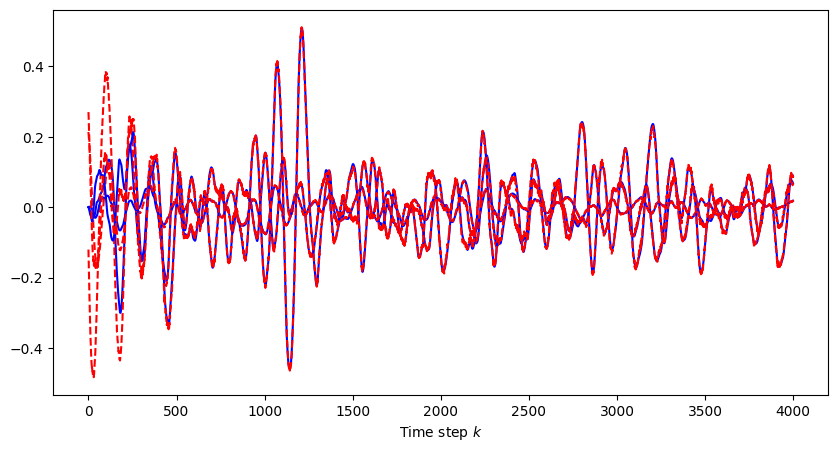

In [247]:
tilde_y_hats = normalizer.inverse_transform_outputs(np.array(tilde_y_hats)).squeeze()
fig, ax = plt.subplots(figsize=(10, 5))
for tilde_y_hat, y in zip(tilde_y_hats[:3], train_dict[0]['outputs'][:3]):
    ax.plot(tilde_y_hat, color='blue')
    ax.plot(y, color='red', linestyle='--')
ax.set_xlabel('Time step $k$')
